# DL PR 6 — Opening the Transformer: Attention, Encoder, Decoder and Inference
** Deep Learning**


In [2]:
import os, time, warnings
import numpy as np, pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

torch.manual_seed(42); np.random.seed(42)
os.makedirs("plots", exist_ok=True)
torch.set_grad_enabled(False)          # inference only, no training anywhere in this notebook

MODEL_SST = "distilbert-base-uncased-finetuned-sst-2-english"
MODEL_GPT2 = "gpt2"
MODEL_T5 = "t5-small"
MODEL_MLM = "distilbert-base-uncased"

def savefig(name):
    plt.tight_layout(); plt.savefig(f"plots/{name}", dpi=150, bbox_inches="tight")
print("torch", torch.__version__)

torch 2.14.0+cpu


# Task 1 — Introduction, History, Pipelines & Tokenizer
**Objective:** run a first pipeline, understand the Transformer's history and trade-offs, and look at tokenisation and model size.
**Expected output:** 5 predictions, timeline and lists, tokens/ids/masks, a padded batch, a config table.

## 1.1 First pipeline

In [3]:
from transformers import pipeline
clf = pipeline("sentiment-analysis", model=MODEL_SST)
sentences = [
    "I absolutely loved this film, the acting was superb.",
    "The delivery was late and the product arrived broken.",
    "The food was not bad at all, I would happily come again.",   # tricky: negation
    "What a waste of two hours; I want my money back.",
    "The new phone is fast, light and the battery lasts all day.",
]
for s, r in zip(sentences, clf(sentences)):
    print(f"{r['label']:9s} {r['score']:.4f}  |  {s}")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

POSITIVE  0.9999  |  I absolutely loved this film, the acting was superb.
NEGATIVE  0.9996  |  The delivery was late and the product arrived broken.
POSITIVE  0.9995  |  The food was not bad at all, I would happily come again.
NEGATIVE  0.9998  |  What a waste of two hours; I want my money back.
NEGATIVE  0.9144  |  The new phone is fast, light and the battery lasts all day.


## 1.2 Introduction & history
| Year | Model / paper | Why it mattered |
|---|---|---|
| 2014–15 | Seq2seq with attention (Bahdanau; Luong) | Decoder could look back at all encoder states instead of one fixed vector, fixing the bottleneck of RNN translation. |
| 2017 | *Attention Is All You Need* (Vaswani et al.) | Removed recurrence completely; attention + feed-forward layers, fully parallel training. |
| 2018 | BERT (encoder) and GPT (decoder) | Showed that pre-training on huge unlabelled text, then fine-tuning, beats task-specific models. |
| 2019 | GPT-2, T5, DistilBERT | Larger generative models, a unified text-to-text framework, and compression by distillation. |
| 2020+ | GPT-3 and later LLMs, Vision Transformer (ViT) | Scaling laws, in-context learning, and Transformers moving to images, audio and proteins. |

**Problem solved over RNN/LSTM:** RNNs read tokens one after another, so training could not be parallelised on GPUs and was slow. Information from early tokens had to survive many steps, giving short effective memory and vanishing gradients on long text. In a Transformer every token connects directly to every other token in one step, so long-range links are short paths and the whole sequence is computed in parallel.

## 1.3 Impact & disadvantages
**Impact:** machine translation; web and enterprise search/ranking; chat assistants; code completion; summarisation; speech recognition; image generation/classification (ViT, diffusion transformers); protein structure prediction (AlphaFold).

**Disadvantages:** attention cost grows quadratically with sequence length; fixed context window; heavy compute and memory; needs huge data; generative models hallucinate; internal behaviour is hard to interpret. *Two of these are measured in Task 6 (quadratic cost / truncation, and hallucination).*

## 1.4 Tokenizer in action

In [4]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(MODEL_SST)
text = "Transformers are surprisingly easy to understand."
enc = tok(text)
print("tokens        :", tok.tokenize(text))
print("input_ids     :", enc["input_ids"])
print("attention_mask:", enc["attention_mask"])
for w in ["electroencephalography", "unbelievably", "tokenization"]:
    print(f"{w!r:28} ->", tok.tokenize(w))

tokens        : ['transformers', 'are', 'surprisingly', 'easy', 'to', 'understand', '.']
input_ids     : [101, 19081, 2024, 10889, 3733, 2000, 3305, 1012, 102]
attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1]
'electroencephalography'     -> ['electro', '##ence', '##pha', '##log', '##raphy']
'unbelievably'               -> ['un', '##bel', '##ie', '##va', '##bly']
'tokenization'               -> ['token', '##ization']


`[CLS]` is added at the start; its final vector is used as the summary of the whole sentence for classification. `[SEP]` marks the end of a sentence (or the boundary between two sentences). **Sub-words** keep the vocabulary small (~30k) while still representing any word: rare or new words are assembled from known pieces (`##` marks a continuation), so there are no unknown-word failures and common pieces get well-trained embeddings.

## 1.5 Batching and padding

In [5]:
batch = tok(["Short one.", "This second sentence is clearly a good deal longer than the first."],
            padding=True, return_tensors="pt")
print("input_ids:\n", batch["input_ids"])
print("attention_mask:\n", batch["attention_mask"])

input_ids:
 tensor([[ 101, 2460, 2028, 1012,  102,    0,    0,    0,    0,    0,    0,    0,
            0,    0,    0],
        [ 101, 2023, 2117, 6251, 2003, 4415, 1037, 2204, 3066, 2936, 2084, 1996,
         2034, 1012,  102]])
attention_mask:
 tensor([[1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])


Tensors in a batch must have equal length, so the shorter sentence is padded with `[PAD]` (id 0). The `attention_mask` is 1 for real tokens and 0 for padding so the model ignores the padding; the effect is shown in Task 4.8.

## 1.6 Model anatomy at a glance

In [6]:
from transformers import AutoModelForSequenceClassification
clf_model = AutoModelForSequenceClassification.from_pretrained(MODEL_SST).eval()
cfg = clf_model.config
print(cfg)
total = sum(p.numel() for p in clf_model.parameters())
print("Total parameters:", f"{total:,}")
for i, (n, p) in enumerate(clf_model.named_parameters()):
    if i >= 15: break
    print(n, tuple(p.shape))
pd.DataFrame({"item": ["layers (n_layers)", "attention heads (n_heads)", "hidden size (dim)",
                       "FFN size (hidden_dim)", "vocab size", "max position embeddings", "total parameters"],
              "value": [cfg.n_layers, cfg.n_heads, cfg.dim, cfg.hidden_dim, cfg.vocab_size,
                        cfg.max_position_embeddings, f"{total:,}"]})

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

DistilBertConfig {
  "activation": "gelu",
  "architectures": [
    "DistilBertForSequenceClassification"
  ],
  "attention_dropout": 0.1,
  "bos_token_id": null,
  "dim": 768,
  "dropout": 0.1,
  "dtype": "float32",
  "eos_token_id": null,
  "finetuning_task": "sst-2",
  "hidden_dim": 3072,
  "id2label": {
    "0": "NEGATIVE",
    "1": "POSITIVE"
  },
  "initializer_range": 0.02,
  "label2id": {
    "NEGATIVE": 0,
    "POSITIVE": 1
  },
  "max_position_embeddings": 512,
  "model_type": "distilbert",
  "n_heads": 12,
  "n_layers": 6,
  "output_past": true,
  "pad_token_id": 0,
  "qa_dropout": 0.1,
  "seq_classif_dropout": 0.2,
  "sinusoidal_pos_embds": false,
  "tie_weights_": true,
  "tie_word_embeddings": true,
  "transformers_version": "5.22.1",
  "vocab_size": 30522
}

Total parameters: 66,955,010
distilbert.embeddings.word_embeddings.weight (30522, 768)
distilbert.embeddings.position_embeddings.weight (512, 768)
distilbert.embeddings.LayerNorm.weight (768,)
distilbert.embeddings.L

,item,value
0,layers (n_layers),6
1,attention heads (n_heads),12
2,hidden size (dim),768
3,FFN size (hidden_dim),3072
4,vocab size,30522
5,max position embeddings,512
6,total parameters,"66,955,010"


# Task 2 — Self-Attention & Scaled Dot-Product Attention
**Objective:** build self-attention from scratch and prove it matches a real model.
**Expected output:** shapes, heatmap, scaling experiment, Luong comparison, order-blindness check, `np.allclose` verification.

## 2.1 The idea
Each token embedding is projected into three vectors: a **Query** (what am I looking for?), a **Key** (what do I offer?) and a **Value** (what do I pass on?). A token's new representation is a **weighted average of all Value vectors**, where the weights come from how well its Query matches every Key (softmax of the dot products). The whole sequence is handled in one matrix multiplication, so — unlike an RNN — all positions are processed **in parallel**.

## 2.2 Scaled dot-product attention from scratch

X        (4, 8)
Q        (4, 8)
K        (4, 8)
V        (4, 8)
scores   (4, 4)
weights  (4, 4)
output   (4, 8)
row sums: [1. 1. 1. 1.] -> all ones: True


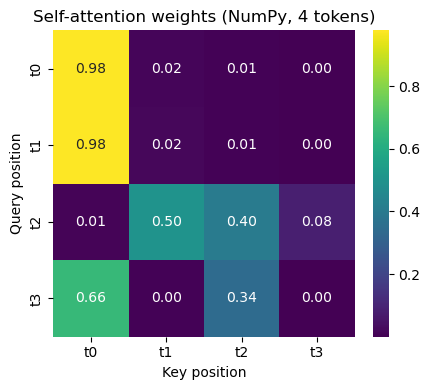

In [7]:
def softmax(x, axis=-1):
    x = x - np.max(x, axis=axis, keepdims=True)      # subtract max for numerical stability
    e = np.exp(x)
    return e / np.sum(e, axis=axis, keepdims=True)

def self_attention(X, Wq, Wk, Wv, mask=None, verbose=False):
    Q, K, V = X @ Wq, X @ Wk, X @ Wv
    d_k = K.shape[-1]
    scores = Q @ K.T / np.sqrt(d_k)
    if mask is not None:
        scores = scores + mask
    W = softmax(scores, axis=-1)
    out = W @ V
    if verbose:
        for n, a in [("X", X), ("Q", Q), ("K", K), ("V", V), ("scores", scores), ("weights", W), ("output", out)]:
            print(f"{n:8s}", a.shape)
    return out, W

rng = np.random.default_rng(42)
X = rng.normal(size=(4, 8))
Wq, Wk, Wv = (rng.normal(size=(8, 8)) for _ in range(3))
out, W = self_attention(X, Wq, Wk, Wv, verbose=True)
print("row sums:", W.sum(axis=1), "-> all ones:", np.allclose(W.sum(axis=1), 1))

plt.figure(figsize=(4.5, 4))
sns.heatmap(W, annot=True, fmt=".2f", cmap="viridis", xticklabels=[f"t{i}" for i in range(4)],
            yticklabels=[f"t{i}" for i in range(4)])
plt.title("Self-attention weights (NumPy, 4 tokens)"); plt.xlabel("Key position"); plt.ylabel("Query position")
savefig("attention_scratch.png"); plt.show()

## 2.3 Why divide by √d_k?

In [8]:
def stats(dk, scale, n=64, trials=20):
    rng = np.random.default_rng(0)
    mx, ent = [], []
    for _ in range(trials):
        Q = rng.normal(size=(n, dk)); K = rng.normal(size=(n, dk))
        s = Q @ K.T
        if scale: s = s / np.sqrt(dk)
        P = softmax(s)
        mx.append(P.max(axis=1).mean())
        ent.append((-(P * np.log(P + 1e-12)).sum(axis=1)).mean())
    return np.mean(mx), np.mean(ent)

rows = []
for dk in [4, 256]:
    for scale in [False, True]:
        m, e = stats(dk, scale)
        rows.append({"d_k": dk, "scaled by 1/sqrt(d_k)": scale, "mean max prob": round(m, 4), "mean entropy": round(e, 4)})
print("Uniform attention over 64 keys would have max prob 0.0156 and entropy", round(np.log(64), 3))
pd.DataFrame(rows)

Uniform attention over 64 keys would have max prob 0.0156 and entropy 4.159


,d_k,scaled by 1/sqrt(d_k),mean max prob,mean entropy
0,4,False,0.2788,2.8018
1,4,True,0.1051,3.7056
2,256,False,0.8977,0.2627
3,256,True,0.1069,3.6825


Dot products of random vectors have variance ≈ d_k, so their magnitude grows with d_k. Large scores push softmax into a **saturated** region: one weight is almost 1 and the rest almost 0 (high max-probability, low entropy), where gradients are close to zero and learning stalls. Dividing by √d_k brings the variance back near 1, keeping attention soft and gradients healthy. The table shows this: without scaling, d_k = 256 is far more peaked than d_k = 4; with scaling both behave similarly.

## 2.4 Self-attention vs Luong attention

In [9]:
rng = np.random.default_rng(1)
enc_states = rng.normal(size=(5, 8))      # 5 encoder hidden states
dec_state = rng.normal(size=(8,))         # one decoder hidden state
scores = enc_states @ dec_state
weights = softmax(scores)
context = weights @ enc_states
print("Luong dot weights:", np.round(weights, 3), "sum =", weights.sum().round(3))
print("context vector shape:", context.shape)

Luong dot weights: [0.003 0.001 0.003 0.992 0.001] sum = 1.0
context vector shape: (8,)


| Aspect | Luong (dot) attention | Self-attention |
|---|---|---|
| Where Q, K, V come from | Query = one decoder hidden state; Keys = Values = encoder hidden states (no learned projections) | Q, K, V are three learned linear projections of the same token embeddings |
| What is attended over | decoder state looks at encoder states | every token looks at every token of the same sequence |
| Needs an RNN? | Yes, the states come from RNN/LSTM | No, only embeddings + attention + FFN |
| Parallelism | Decoder is sequential step by step | Whole sequence computed at once |
| Place in architecture | Between encoder and decoder of a seq2seq model | Inside every encoder/decoder block (and decoder cross-attention is the Transformer's version of Luong) |

## 2.5 Attention is order-blind

In [10]:
perm = np.array([2, 0, 3, 1])
out_orig, _ = self_attention(X, Wq, Wk, Wv)
out_perm, _ = self_attention(X[perm], Wq, Wk, Wv)
print("permuted output == original output re-permuted:", np.allclose(out_perm, out_orig[perm]))

permuted output == original output re-permuted: True


Shuffling the input rows only shuffles the output rows in the same way: the mechanism treats the input as a **set**, with no idea which token came first. "dog bites man" and "man bites dog" would look the same, which is why Task 3 adds positional information.

## 2.6 Verify against a real model (DistilBERT, layer 0, head 0)

In [11]:
from transformers import AutoModel
enc_model = AutoModel.from_pretrained(MODEL_SST, attn_implementation="eager").eval()
sent = "The animal did not cross the street because it was too tired."
inp = tok(sent, return_tensors="pt")
out_hf = enc_model(**inp, output_hidden_states=True, output_attentions=True)

att0 = enc_model.transformer.layer[0].attention       # modules: q_lin, k_lin, v_lin, out_lin
x = out_hf.hidden_states[0]                           # embedding output = input of layer 0
H, dh = 12, 64
split = lambda t: t.view(1, -1, H, dh).transpose(1, 2)
q, k = split(att0.q_lin(x)), split(att0.k_lin(x))
scores = q @ k.transpose(-1, -2) / np.sqrt(dh)       # no padding here, so no mask to add
mine = torch.softmax(scores, dim=-1)[0, 0].numpy()
real = out_hf.attentions[0][0, 0].numpy()
print("allclose (atol=1e-4):", np.allclose(mine, real, atol=1e-4))
print("max abs difference  :", np.abs(mine - real).max())

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased-finetuned-sst-2-english
Key                   | Status     |  | 
----------------------+------------+--+-
pre_classifier.bias   | UNEXPECTED |  | 
pre_classifier.weight | UNEXPECTED |  | 
classifier.bias       | UNEXPECTED |  | 
classifier.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


allclose (atol=1e-4): True
max abs difference  : 0.0


A match (difference ~1e-7) proves that my NumPy-style equation `softmax(QKᵀ/√d_k)` is exactly what the pretrained model computes: the real model has no hidden extra step in the attention weights. It also shows that heads are slices of size 64 of the 768-dim projections. (If a newer `transformers` version renames modules, use `print(enc_model)` to find the right attribute names.)

# Task 3 — Multi-Head Attention, Positional Encoding & Layer Normalization
**Objective:** see why several heads are used, how position is injected, and how LayerNorm differs from BatchNorm.
**Expected output:** real attention plots, entropy bars, PE heatmaps, LayerNorm checks.

## 3.1 Multi-head attention
One attention pattern per layer is too limiting: a token may need to link to a noun, to the previous word and to punctuation at the same time. With *h* heads, `d_model` is split into *h* smaller subspaces (DistilBERT: 768 = 12 × 64). Each head has its own Q, K, V projections and learns its own pattern; the head outputs are **concatenated** and mixed by an **output projection** (`out_lin`). Because each head works in a smaller dimension, the total computation is about the same as a single big head.

## 3.2 Real attention heads

number of layers: 6 | each tensor shape: (1, 12, 15, 15)


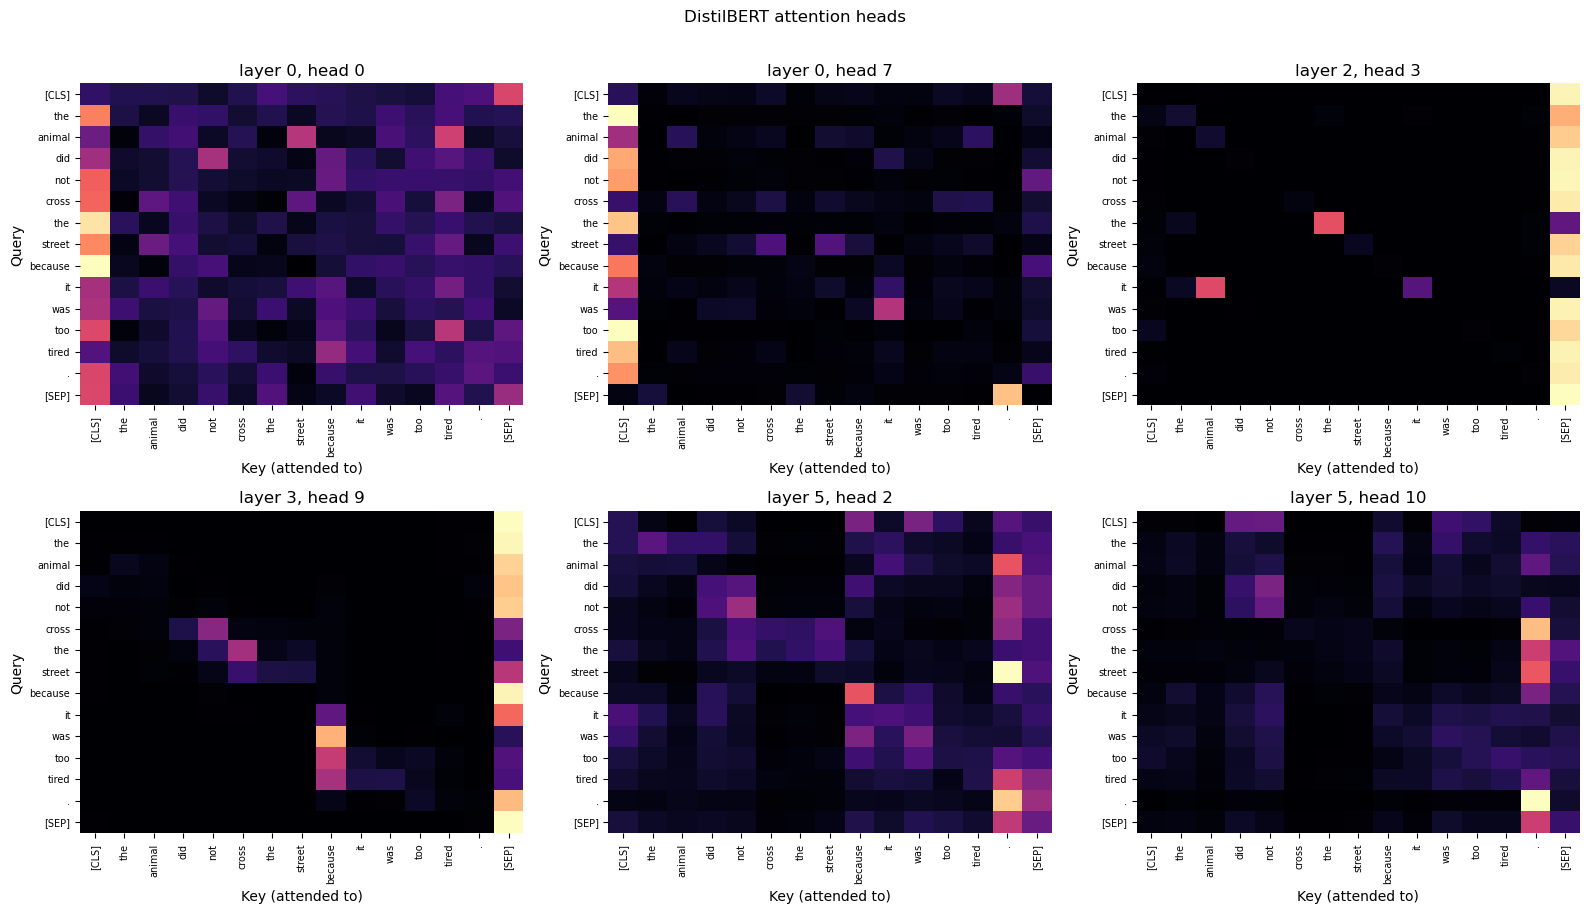

L0H0: mean attn to previous token=0.06 | to [CLS]/[SEP]=0.27 | 'it' attends to ['[CLS]', 'tired', 'because']
L0H7: mean attn to previous token=0.15 | to [CLS]/[SEP]=0.55 | 'it' attends to ['[CLS]', 'it', '[SEP]']
L2H3: mean attn to previous token=0.00 | to [CLS]/[SEP]=0.86 | 'it' attends to ['animal', 'it', 'the']
L3H9: mean attn to previous token=0.11 | to [CLS]/[SEP]=0.65 | 'it' attends to ['[SEP]', 'because', 'tired']
L5H2: mean attn to previous token=0.08 | to [CLS]/[SEP]=0.20 | 'it' attends to ['it', '[CLS]', 'because']
L5H10: mean attn to previous token=0.08 | to [CLS]/[SEP]=0.13 | 'it' attends to ['not', 'tired', '.']


In [12]:
atts = out_hf.attentions
print("number of layers:", len(atts), "| each tensor shape:", tuple(atts[0].shape))
tokens = tok.convert_ids_to_tokens(inp["input_ids"][0])
heads = [(0, 0), (0, 7), (2, 3), (3, 9), (5, 2), (5, 10)]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (l, h) in zip(axes.ravel(), heads):
    sns.heatmap(atts[l][0, h].numpy(), ax=ax, cmap="magma", cbar=False,
                xticklabels=tokens, yticklabels=tokens)
    ax.set_title(f"layer {l}, head {h}"); ax.set_xlabel("Key (attended to)"); ax.set_ylabel("Query")
    ax.tick_params(labelsize=7)
plt.suptitle("DistilBERT attention heads", y=1.01)
savefig("attention_heads.png"); plt.show()

# numeric summary to support the written description
it = tokens.index("it")
for l, h in heads:
    A = atts[l][0, h].numpy()
    prev = np.mean([A[i, i-1] for i in range(1, len(tokens))])
    special = A[:, [0, -1]].sum(axis=1).mean()
    top = [tokens[j] for j in np.argsort(A[it])[::-1][:3]]
    print(f"L{l}H{h}: mean attn to previous token={prev:.2f} | to [CLS]/[SEP]={special:.2f} | 'it' attends to {top}")

**Behaviours to describe (confirm against your own plots and the numbers above):**
1. **Previous-/neighbouring-token heads:** a bright line just below or beside the diagonal, i.e. each token mostly looks at the word before (or after) it — local syntax.
2. **[CLS]/[SEP] "sink" heads:** most queries put large weight on the first or last special token, a kind of "no-op" resting place for tokens with nothing useful to attend to.
3. **Linking heads:** in some heads the row for `it` puts weight on `animal`/`street`/`tired`, a coreference-like link (not guaranteed in every head — read the printed top-3 for `it`).

## 3.3 Head diversity (attention entropy)

layer 0: min=0.55 max=2.49 mean=1.69
layer 5: min=1.76 max=2.29 mean=2.01


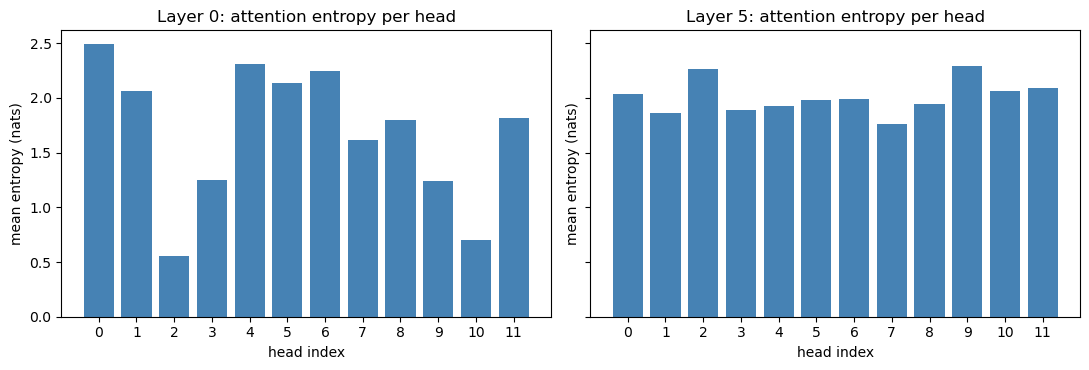

In [13]:
def head_entropy(A):                      # A: (heads, T, T)
    return (-(A * np.log(A + 1e-12)).sum(-1)).mean(-1)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, l in zip(axes, [0, 5]):
    e = head_entropy(atts[l][0].numpy())
    ax.bar(range(12), e, color="steelblue"); ax.set_title(f"Layer {l}: attention entropy per head")
    ax.set_xlabel("head index"); ax.set_ylabel("mean entropy (nats)"); ax.set_xticks(range(12))
    print(f"layer {l}: min={e.min():.2f} max={e.max():.2f} mean={e.mean():.2f}")
savefig("head_entropy.png"); plt.show()

Compare the printed means: in this one sentence the two layers differ modestly, so I only claim that heads within a layer vary a lot in how focused they are (low entropy = focused, high = spread out); I would need many sentences to say more.

## 3.4 Sinusoidal positional encoding from scratch

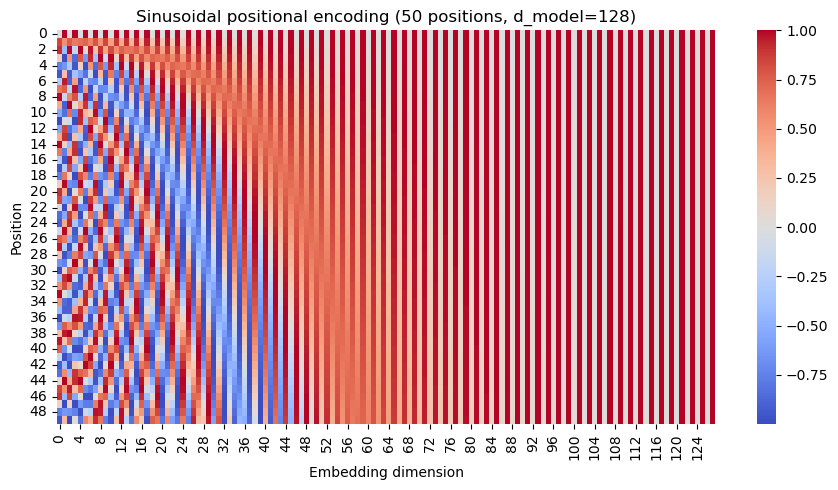

In [14]:
def positional_encoding(n_pos, d_model):
    pos = np.arange(n_pos)[:, None]
    i = np.arange(0, d_model, 2)[None, :]
    angle = pos / np.power(10000, i / d_model)
    PE = np.zeros((n_pos, d_model))
    PE[:, 0::2] = np.sin(angle)
    PE[:, 1::2] = np.cos(angle)
    return PE

PE = positional_encoding(50, 128)
plt.figure(figsize=(9, 5))
sns.heatmap(PE, cmap="coolwarm", center=0)
plt.title("Sinusoidal positional encoding (50 positions, d_model=128)")
plt.xlabel("Embedding dimension"); plt.ylabel("Position")
savefig("positional_encoding.png"); plt.show()

Each dimension pair uses a sine/cosine of a different frequency (fast at low dimensions, slow at high ones), like digits of a clock. Together they give **every position a unique pattern**, work for lengths not seen in training, and because `sin(a+b)` and `cos(a+b)` are linear in `sin a, cos a`, a **relative offset is a simple linear function** of the encoding, easy for attention to learn.

## 3.5 Position makes identical words different

In [15]:
cos = lambda a, b: float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))
e = np.random.default_rng(3).normal(size=128)
x3, x20 = e + PE[3], e + PE[20]
print("cosine similarity WITHOUT PE:", cos(e, e))
print("cosine similarity WITH PE (pos 3 vs 20):", round(cos(x3, x20), 4))

cosine similarity WITHOUT PE: 1.0
cosine similarity WITH PE (pos 3 vs 20): 0.882


Without PE the same word at two places is the same vector (similarity 1.0), so attention (Task 2.5) cannot tell the places apart. After adding PE, the two copies differ, so their Queries/Keys differ and attention can depend on word order. That removes the order-blindness: shuffling the sentence now changes the inputs and therefore the outputs.

## 3.6 Learned positional embeddings in DistilBERT

shape: (512, 768)


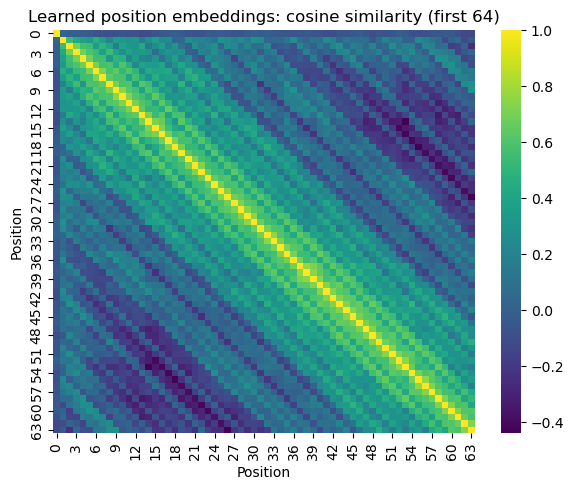

In [16]:
P = clf_model.distilbert.embeddings.position_embeddings.weight.detach().numpy()
print("shape:", P.shape)
P64 = P[:64]; Pn = P64 / np.linalg.norm(P64, axis=1, keepdims=True)
plt.figure(figsize=(6, 5))
sns.heatmap(Pn @ Pn.T, cmap="viridis"); plt.title("Learned position embeddings: cosine similarity (first 64)")
plt.xlabel("Position"); plt.ylabel("Position")
savefig("learned_positions.png"); plt.show()

BERT-style models **learn** one vector per position instead of using sinusoids; nearby positions end up similar (bright band around the diagonal). The table has only **512 rows**, so there is no vector for position 513 — this is the origin of the 512-token context limit. T5 instead uses **relative position biases** added to attention scores (seen in Task 5).

## 3.7 Layer normalization from scratch

In [17]:
def layer_norm(x, gamma=1.0, beta=0.0, eps=1e-5):
    mu = x.mean(axis=-1, keepdims=True)          # over FEATURES of each token
    var = x.var(axis=-1, keepdims=True)
    return gamma * (x - mu) / np.sqrt(var + eps) + beta

M = np.random.default_rng(5).normal(loc=3, scale=2, size=(4, 8))
ln = layer_norm(M)
print("per-token mean:", ln.mean(axis=1).round(6))
print("per-token std :", ln.std(axis=1).round(4))
torch_ln = torch.nn.LayerNorm(8)                 # gamma=1, beta=0 by default
print("matches torch.nn.LayerNorm:", torch.allclose(torch.tensor(ln, dtype=torch.float32), torch_ln(torch.tensor(M, dtype=torch.float32)), atol=1e-5))

per-token mean: [-0.  0. -0. -0.]
per-token std : [1. 1. 1. 1.]
matches torch.nn.LayerNorm: True


## 3.8 LayerNorm vs BatchNorm

In [18]:
bn = (M - M.mean(axis=0, keepdims=True)) / np.sqrt(M.var(axis=0, keepdims=True) + 1e-5)   # per FEATURE across tokens
print("BatchNorm  per-token mean:", bn.mean(axis=1).round(3))
print("BatchNorm  per-token std :", bn.std(axis=1).round(3), "<- NOT normalised per token")
print("BatchNorm  per-feature mean:", bn.mean(axis=0).round(6))
g = clf_model.distilbert.embeddings.LayerNorm
print("DistilBERT embedding LayerNorm gamma:", tuple(g.weight.shape), "beta:", tuple(g.bias.shape))

BatchNorm  per-token mean: [ 0.019  0.343 -0.105 -0.257]
BatchNorm  per-token std : [1.047 1.229 0.431 1.007] <- NOT normalised per token
BatchNorm  per-feature mean: [ 0. -0.  0.  0.  0.  0.  0.  0.]
DistilBERT embedding LayerNorm gamma: (768,) beta: (768,)


# Task 4 — Transformer Encoder Architecture & Masked Self-Attention
**Objective:** read the real encoder, locate its parameters, and compare bidirectional and causal attention.
**Expected output:** module table, parameter chart, fill-mask, heatmaps, mask checks.

## 4.1 Encoder architecture
Input embeddings + positional information → *N* identical blocks. Each block: **multi-head self-attention → residual connection + LayerNorm → position-wise feed-forward network (expand, non-linearity, project back) → residual connection + LayerNorm**. DistilBERT has 6 such blocks, each with 12 heads and an FFN 768 → 3072 → 768 with GELU. "Encoder" means every token can see every other token in **both directions**.

## 4.2 Print and read the real encoder

In [19]:
print(clf_model.distilbert)

DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=Tru

| Component | Module name in DistilBERT |
|---|---|
| Token embedding | `embeddings.word_embeddings` (30522 × 768) |
| Position embedding | `embeddings.position_embeddings` (512 × 768) |
| Embedding LayerNorm | `embeddings.LayerNorm` |
| Attention block | `transformer.layer[i].attention` → `q_lin`, `k_lin`, `v_lin`, `out_lin` |
| Feed-forward block | `transformer.layer[i].ffn` → `lin1` (768→3072), activation (GELU), `lin2` (3072→768) |
| Two LayerNorms per block | `sa_layer_norm` (after attention), `output_layer_norm` (after FFN) |

## 4.3 Where do the parameters live?

                     parameters  share %
embeddings             23834112    35.60
attention              14174208    21.17
feed-forward           28334592    42.32
layer norms               19968     0.03
classification head      592130     0.88 
total: 66955010 (matches Task 1.6: True )


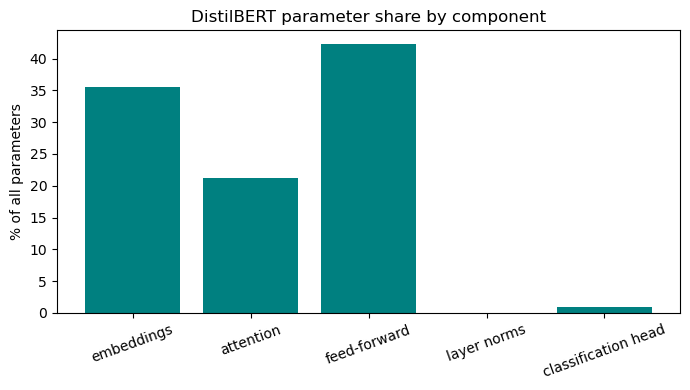

In [20]:
groups = {"embeddings": 0, "attention": 0, "feed-forward": 0, "layer norms": 0, "classification head": 0}
for n, p in clf_model.named_parameters():
    if "LayerNorm" in n or "layer_norm" in n: groups["layer norms"] += p.numel()
    elif "embeddings" in n: groups["embeddings"] += p.numel()
    elif "attention" in n: groups["attention"] += p.numel()
    elif "ffn" in n: groups["feed-forward"] += p.numel()
    else: groups["classification head"] += p.numel()
tot = sum(groups.values())
df = pd.DataFrame({"parameters": groups}); df["share %"] = (100 * df["parameters"] / tot).round(2)
print(df, "\ntotal:", tot, "(matches Task 1.6:", tot == sum(p.numel() for p in clf_model.parameters()), ")")
plt.figure(figsize=(7, 4)); plt.bar(df.index, df["share %"], color="teal")
plt.title("DistilBERT parameter share by component"); plt.ylabel("% of all parameters"); plt.xticks(rotation=20)
savefig("parameter_distribution.png"); plt.show()

The **embeddings** (a 30k-word vocabulary × 768) and the **feed-forward** blocks hold most parameters; attention is smaller. Since FFNs hold a large share, they are widely believed to act as the model's "memory" for facts and patterns, while attention mostly routes information between tokens.

## 4.4 Fill-mask

In [21]:
fm = pipeline("fill-mask", model=MODEL_MLM)
for s in ["The capital of France is [MASK].", "She opened the [MASK] and started to read the first page.",
          "The doctor told him to take the [MASK] twice a day."]:
    print(s)
    for r in fm(s, top_k=3): print(f"   {r['token_str']:12s} {r['score']:.3f}")

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

The capital of France is [MASK].
   marseille    0.143
   nantes       0.090
   toulouse     0.088
She opened the [MASK] and started to read the first page.
   folder       0.134
   book         0.123
   envelope     0.116
The doctor told him to take the [MASK] twice a day.
   medication   0.179
   pill         0.167
   pills        0.111


The prediction for the second and third sentences relies on words **after** the mask ("started to read", "twice a day") as well as before it — the bidirectional behaviour of an encoder.

## 4.5 Bidirectional attention heatmap

max above diagonal: 0.3409 | max below diagonal: 0.47


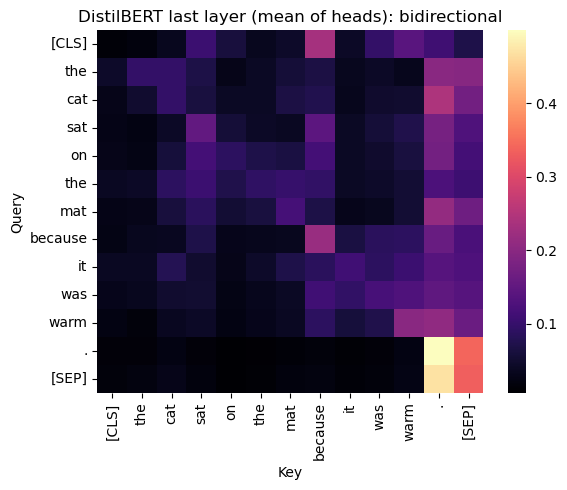

In [22]:
sent4 = "The cat sat on the mat because it was warm."
i4 = tok(sent4, return_tensors="pt"); t4 = tok.convert_ids_to_tokens(i4["input_ids"][0])
A_enc = enc_model(**i4, output_attentions=True).attentions[-1][0].mean(0).numpy()
print("max above diagonal:", np.triu(A_enc, 1).max().round(4), "| max below diagonal:", np.tril(A_enc, -1).max().round(4))
plt.figure(figsize=(6, 5)); sns.heatmap(A_enc, xticklabels=t4, yticklabels=t4, cmap="magma")
plt.title("DistilBERT last layer (mean of heads): bidirectional"); plt.xlabel("Key"); plt.ylabel("Query")
savefig("bidirectional_attention.png"); plt.show()

Both triangles contain weight: each token looks left **and** right. This is not allowed in a language model that must predict the next word, since the future tokens would reveal the answer — hence **masked (causal) self-attention**.

## 4.6 Causal mask from scratch

lower-triangular: True | rows sum to 1: True


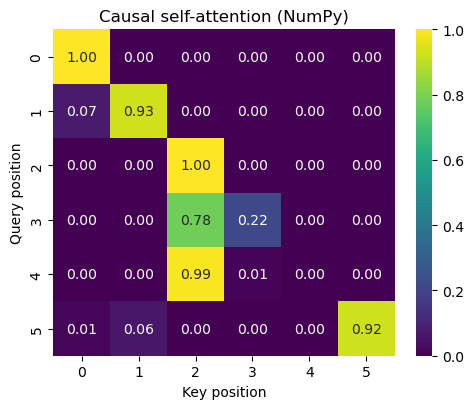

In [23]:
T = 6
rng = np.random.default_rng(7)
X6 = rng.normal(size=(T, 8)); Wq6, Wk6, Wv6 = (rng.normal(size=(8, 8)) for _ in range(3))
mask = np.triu(np.full((T, T), -np.inf), k=1)           # -inf above the diagonal, 0 on/below
_, Wc = self_attention(X6, Wq6, Wk6, Wv6, mask=mask)
print("lower-triangular:", np.allclose(np.triu(Wc, 1), 0), "| rows sum to 1:", np.allclose(Wc.sum(1), 1))
plt.figure(figsize=(5, 4.2)); sns.heatmap(Wc, annot=True, fmt=".2f", cmap="viridis")
plt.title("Causal self-attention (NumPy)"); plt.xlabel("Key position"); plt.ylabel("Query position")
savefig("causal_mask.png"); plt.show()

Adding −∞ **before** the softmax makes `exp(−∞)=0`, so forbidden positions get exactly zero weight **and the remaining weights still renormalise to sum to 1**. Zeroing weights after the softmax would leave rows summing to less than 1 (needing a re-normalisation) and, in training, it would not stop the information flow properly through the score computation.

## 4.7 Causal mask in a real decoder (GPT-2)

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

np.triu(attn, k=1).max() = 0.0 -> < 1e-6: True


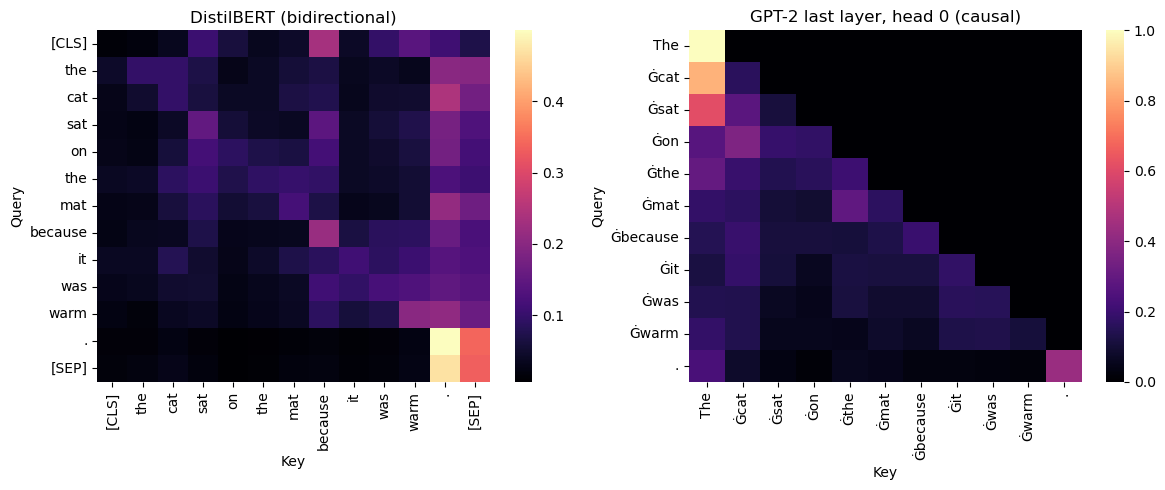

In [24]:
from transformers import AutoModelForCausalLM
gtok = AutoTokenizer.from_pretrained(MODEL_GPT2); gtok.pad_token = gtok.eos_token
gpt = AutoModelForCausalLM.from_pretrained(MODEL_GPT2, attn_implementation="eager").eval()
gi = gtok("The cat sat on the mat because it was warm.", return_tensors="pt")
ga = gpt(**gi, output_attentions=True).attentions[-1][0, 0].numpy()
gt = gtok.convert_ids_to_tokens(gi["input_ids"][0])
print("np.triu(attn, k=1).max() =", np.triu(ga, 1).max(), "-> < 1e-6:", np.triu(ga, 1).max() < 1e-6)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(A_enc, ax=ax[0], xticklabels=t4, yticklabels=t4, cmap="magma"); ax[0].set_title("DistilBERT (bidirectional)")
sns.heatmap(ga, ax=ax[1], xticklabels=gt, yticklabels=gt, cmap="magma"); ax[1].set_title("GPT-2 last layer, head 0 (causal)")
for a in ax: a.set_xlabel("Key"); a.set_ylabel("Query")
savefig("bidirectional_vs_causal.png"); plt.show()

GPT-2's matrix is lower-triangular like my NumPy version; DistilBERT's fills both triangles.

## 4.8 Padding mask vs causal mask

In [25]:
pb = tok(["Short one.", "This second sentence is clearly a good deal longer than the first."], padding=True, return_tensors="pt")
pa = enc_model(**pb, output_attentions=True).attentions[-1]            # (2, 12, T, T)
pad_pos = (pb["attention_mask"][0] == 0).nonzero().flatten()
print("padding positions of sentence 0:", pad_pos.tolist())
print("max attention received by padding keys:", pa[0][:, :, pad_pos].max().item())

padding positions of sentence 0: [5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
max attention received by padding keys: 0.0


# Task 5 — Cross-Attention, Decoder Architecture & Inference
**Objective:** study the decoder and cross-attention, then run inference token by token.
**Expected output:** translation/summary, cross-attention heatmap, greedy loop, decoding table, cache timing, family table.

## 5.1 Decoder architecture
The original decoder block: **masked multi-head self-attention → add & norm → cross-attention over the encoder output → add & norm → feed-forward → add & norm**; after the last block a **linear layer + softmax over the vocabulary** gives next-token probabilities.

Three families: **encoder-only** (BERT/DistilBERT: bidirectional, understanding tasks); **decoder-only** (GPT-2: drops cross-attention and uses only causal self-attention, generation); **encoder-decoder** (T5: keeps both, text-to-text tasks like translation and summarisation).

## 5.2 Cross-attention
In cross-attention the **Queries come from the decoder** (what the target sentence being written needs now), while the **Keys and Values come from the encoder output** (the source sentence). It lets the decoder look at the source while it writes each target word, deciding which source words matter for the next output word. It is the Transformer version of Luong attention (Task 2.4): decoder state as query, encoder states as keys/values, but with learned projections and several heads.

## 5.3 Run an encoder-decoder model

In [27]:
from transformers import AutoTokenizer, T5ForConditionalGeneration

ttok = AutoTokenizer.from_pretrained(MODEL_T5)
t5_gen = T5ForConditionalGeneration.from_pretrained(MODEL_T5).eval()

def t5_run(prefix, text, **gen_kwargs):
    inputs = ttok(prefix + text, return_tensors="pt", truncation=True, max_length=512)
    out = t5_gen.generate(**inputs, **gen_kwargs)
    return ttok.decode(out[0], skip_special_tokens=True)

def translate(text):
    return t5_run("translate English to French: ", text, max_new_tokens=128, num_beams=4)

def summarize(text, max_length=60, min_length=20):
    return t5_run("summarize: ", text, max_length=max_length, min_length=min_length,
                  num_beams=4, early_stopping=True)

for s in ["The weather is beautiful today.", "I would like a cup of coffee, please.", "Where is the nearest train station?"]:
    print(s, "->", translate(s))

paragraph = ("Solar power capacity grew faster last year than in any previous year, driven mainly by falling panel prices "
 "and new installations in Asia and Europe. Analysts say the cost of generating electricity from sunlight has dropped by "
 "more than eighty percent in a decade, making it cheaper than coal in many regions. However, grid operators warn that "
 "the supply of solar electricity peaks at midday, when demand is often lower, so large amounts of battery storage and "
 "better transmission lines are needed. Several governments have announced subsidies for home batteries, while utilities "
 "are testing software that shifts industrial demand to sunny hours. Environmental groups welcomed the growth but noted "
 "that the manufacturing of panels still depends on energy-intensive processes and that recycling of old panels is only "
 "beginning to scale up in most countries.")
summ = summarize(paragraph, max_length=60, min_length=20)
print("\nSUMMARY:", summ)
print("input words:", len(paragraph.split()), "| summary words:", len(summ.split()))

tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  242MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

The weather is beautiful today. -> Le temps est beau aujourd'hui.
I would like a cup of coffee, please. -> Je voudrais une tasse de café, je vous prie.
Where is the nearest train station? -> Où est la gare la plus proche?

SUMMARY: solar power capacity grew faster last year than in any previous year. the cost of generating electricity from sunlight has dropped by more than eighty percent in a decade. grid operators warn that the supply of solar electricity peaks at midday.
input words: 134 | summary words: 41


## 5.4 Extract and plot cross-attention

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

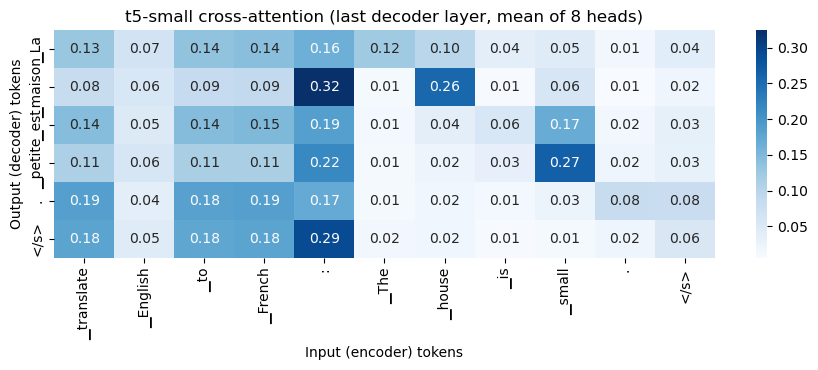

▁La        attends most to :
▁maison    attends most to :
▁est       attends most to :
▁petite    attends most to ▁small
.          attends most to ▁French
</s>       attends most to :


In [29]:
from transformers import T5ForConditionalGeneration
ttok = AutoTokenizer.from_pretrained(MODEL_T5)
t5 = T5ForConditionalGeneration.from_pretrained(MODEL_T5, attn_implementation="eager").eval()
src = "translate English to French: The house is small."
ids = ttok(src, return_tensors="pt").input_ids
labels = ttok("La maison est petite.", return_tensors="pt").input_ids
o = t5(input_ids=ids, labels=labels, output_attentions=True)
ca = o.cross_attentions[-1][0].mean(0).numpy()            # last decoder layer, mean of 8 heads -> (tgt, src)
src_t = ttok.convert_ids_to_tokens(ids[0]); tgt_t = ttok.convert_ids_to_tokens(labels[0])
plt.figure(figsize=(9, 3.8)); sns.heatmap(ca, xticklabels=src_t, yticklabels=tgt_t, cmap="Blues", annot=True, fmt=".2f")
plt.title("t5-small cross-attention (last decoder layer, mean of 8 heads)")
plt.xlabel("Input (encoder) tokens"); plt.ylabel("Output (decoder) tokens")
savefig("cross_attention.png"); plt.show()
for r, t in enumerate(tgt_t): print(f"{t:10s} attends most to {src_t[ca[r].argmax()]}")

**Reading the heatmap:** rows are the French output tokens, columns the English input tokens. Look at where the strongest cell of each row sits: e.g. `▁maison` should focus on `▁house` and `▁petite` on `▁small`, with `▁La` and the final punctuation attending to the article/period or the end token `</s>`. In practice, last-layer, head-averaged cross-attention in a small model is only a **rough** alignment: some rows put much weight on `</s>` or the task prefix, so state honestly which words aligned sensibly in *your* plot and which did not.

## 5.5 Inference is autoregressive — manual greedy loop

In [30]:
prompt = "Artificial intelligence will"
ids = gtok(prompt, return_tensors="pt").input_ids
cur = ids.clone()
for _ in range(20):
    logits = gpt(cur).logits[:, -1, :]
    nxt = logits.argmax(dim=-1, keepdim=True)
    cur = torch.cat([cur, nxt], dim=1)
manual = gtok.decode(cur[0])
auto = gtok.decode(gpt.generate(ids, attention_mask=torch.ones_like(ids), max_new_tokens=20, do_sample=False,
                                pad_token_id=gtok.eos_token_id)[0])
print("MANUAL:", manual); print("GENERATE:", auto); print("identical:", manual == auto)

MANUAL: Artificial intelligence will be able to do things like search for and find people, and to do things like find out who
GENERATE: Artificial intelligence will be able to do things like search for and find people, and to do things like find out who
identical: True


A decoder produces **one token at a time**: it predicts a distribution for the next token from the last position, one token is chosen, appended to the input, and the whole thing is fed back to predict the following one. Generation is therefore sequential even though training of a Transformer is parallel.

## 5.6 Decoding strategies

In [31]:
def gen(**kw):
    seed = kw.pop("seed", None)
    if seed is not None: torch.manual_seed(seed)
    o = gpt.generate(ids, attention_mask=torch.ones_like(ids), max_new_tokens=40, pad_token_id=gtok.eos_token_id, **kw)
    return gtok.decode(o[0], skip_special_tokens=True).replace("\n", " ")
res = {
 "(a) greedy": gen(do_sample=False),
 "(b) beam search (5)": gen(do_sample=False, num_beams=5, early_stopping=True),
 "(c) temp 0.7, seed 1": gen(do_sample=True, temperature=0.7, seed=1),
 "(c) temp 0.7, seed 2": gen(do_sample=True, temperature=0.7, seed=2),
 "(d) temp 1.5, seed 1": gen(do_sample=True, temperature=1.5, seed=1),
 "(d) temp 1.5, seed 2": gen(do_sample=True, temperature=1.5, seed=2),
 "(e) top_k=50, top_p=0.9": gen(do_sample=True, top_k=50, top_p=0.9, seed=1),
}
pd.set_option("display.max_colwidth", 400)
pd.DataFrame({"output": res})

,output
(a) greedy,"Artificial intelligence will be able to do things like search for and find people, and to do things like find out who's in the right place at the right time. ""We're going to be able to"
(b) beam search (5),"Artificial intelligence will be the next big thing, and it's going to take a lot of work to get there. ""I think it's going to take a lot of work to get there,"" he said"
"(c) temp 0.7, seed 1","Artificial intelligence will help us solve difficult problems, and it will help us solve problems that we don't understand."" ""It's going to be a very big world,"" said Dr. Michael S. White,"
"(c) temp 0.7, seed 2",Artificial intelligence will not be able to solve problems that have never been solved. The researchers note that the human brain is the primary control system for the overall cognitive functions of the brain. But the problem is that
"(d) temp 1.5, seed 1",Artificial intelligence will help with our search queries and search for information on our current products while we are working to add new applications so the system won't need maintenance of itself. This could take several and sometimes multiple years after
"(d) temp 1.5, seed 2",Artificial intelligence will not be able to predict what happens in the future because technology will likely just take a little step back from today as people discover new methods like machine learning are increasingly capable of extracting some kinds of input.
"(e) top_k=50, top_p=0.9","Artificial intelligence will help with our search, and perhaps even help us decide which products to buy and which ones not to buy at the moment. I suspect this technology will have its future in the form of advertising, or"


**Temperature** rescales logits: low (0.7) sharpens the distribution (safer, more repetitive text), high (1.5) flattens it (more varied but often incoherent). The two seeds show that sampling changes between runs while greedy/beam are deterministic. **Top-k** keeps only the k most likely tokens and **top-p** (nucleus) keeps the smallest set whose probability sums to p; both cut off the unlikely tail so sampling stays varied but sensible. Greedy and beam search often fall into repetition loops, which you can see in the table.

## 5.7 KV-cache speed-up

In [32]:
def timed(use_cache, runs=3):
    ts = []
    for _ in range(runs):
        t = time.perf_counter()
        gpt.generate(ids, attention_mask=torch.ones_like(ids), max_new_tokens=100, min_new_tokens=100,
                     do_sample=False, use_cache=use_cache, pad_token_id=gtok.eos_token_id)
        ts.append(time.perf_counter() - t)
    return np.mean(ts)
t_c, t_n = timed(True), timed(False)
print(f"with cache: {t_c:.2f}s | without cache: {t_n:.2f}s | speed-up: {t_n / t_c:.1f}x")

with cache: 5.29s | without cache: 10.89s | speed-up: 2.1x


Keys and values of earlier tokens never change when a new token is appended, so they can be **stored** and only the new token's Q, K, V need computing each step, instead of re-running the whole sequence. This turns each step from O(n) token computations to O(1) new ones and is the main speed trick of Transformer inference (the price is extra memory).

## 5.8 Model-family summary
| | DistilBERT | GPT-2 | T5-small |
|---|---|---|---|
| Family | encoder-only | decoder-only | encoder-decoder |
| Attention types | bidirectional self-attention | causal (masked) self-attention | encoder self-attn, causal decoder self-attn, cross-attention |
| Generates text? | No (classifies / fills masks) | Yes | Yes (conditioned on input) |
| Position scheme | learned absolute (512) | learned absolute (1024) | relative position biases |
| Typical tasks | classification, NER, search | text generation, completion | translation, summarisation |
| Example here | sentiment, fill-mask (Tasks 1, 4) | greedy loop, decoding, KV-cache (Task 5) | translation, summary, cross-attention plot (Task 5) |

# Task 6 — Mini Application, Evaluation & Disadvantages in Practice
**Objective:** evaluate the pretrained model honestly, measure two disadvantages, and wrap the models in a small tool.
**Expected output:** metrics, truncation and timing plots, hallucination grades, `text_toolkit()` table, reflection.

## 6.1 Evaluate the pretrained sentiment model

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

accuracy 0.870 | precision 0.889 | recall 0.833 | F1 0.860 | time 43.3s


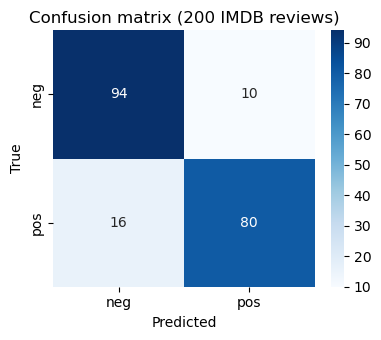

In [34]:
from datasets import load_dataset
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

ds = load_dataset("stanfordnlp/imdb", split="test").shuffle(seed=42).select(range(200))
texts, y_true = list(ds["text"]), np.array(ds["label"])

def evaluate(max_len, batch_size=16):
    t = time.perf_counter()
    preds = []
    for i in range(0, len(texts), batch_size):
        b = tok(texts[i:i + batch_size], truncation=True, max_length=max_len,
                padding=True, return_tensors="pt")
        with torch.no_grad():
            logits = clf_model(**b).logits
        preds.extend(logits.argmax(dim=-1).tolist())     # 0 = NEGATIVE, 1 = POSITIVE
    return np.array(preds), time.perf_counter() - t

y_pred, secs512 = evaluate(512)
print(f"accuracy {accuracy_score(y_true, y_pred):.3f} | precision {precision_score(y_true, y_pred):.3f} | "
      f"recall {recall_score(y_true, y_pred):.3f} | F1 {f1_score(y_true, y_pred):.3f} | time {secs512:.1f}s")
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(4, 3.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["neg", "pos"], yticklabels=["neg", "pos"])
plt.title("Confusion matrix (200 IMDB reviews)"); plt.xlabel("Predicted"); plt.ylabel("True")
savefig("confusion_matrix.png"); plt.show()

Nothing was trained here: the model was fine-tuned earlier on SST-2 (short movie-review sentences), so IMDB (long full reviews) is a different dataset and the score shows how well the model transfers.

## 6.2 Effect of truncation length

max_length= 64: accuracy=0.750, time=4.5s
max_length=128: accuracy=0.775, time=8.5s
max_length=256: accuracy=0.840, time=17.2s
max_length=512: accuracy=0.870, time=36.8s
reviews longer than 512 tokens: 18/200 | median length 207 tokens


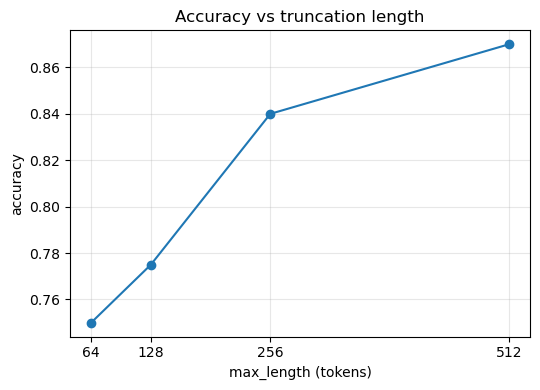

In [36]:
lens, accs, times = [64, 128, 256, 512], [], []
for L in lens:
    y, s = evaluate(L); accs.append(accuracy_score(y_true, y)); times.append(s)
    print(f"max_length={L:3d}: accuracy={accs[-1]:.3f}, time={s:.1f}s")
n_tok = [len(x) for x in tok(texts, truncation=False)["input_ids"]]
over = int(np.sum(np.array(n_tok) > 512))
print(f"reviews longer than 512 tokens: {over}/200 | median length {int(np.median(n_tok))} tokens")
plt.figure(figsize=(5.5, 4)); plt.plot(lens, accs, "o-"); plt.xlabel("max_length (tokens)"); plt.ylabel("accuracy")
plt.title("Accuracy vs truncation length"); plt.xticks(lens); plt.grid(alpha=.3)
savefig("truncation_accuracy.png"); plt.show()

Read the printed numbers: a small window (64 tokens) keeps only the beginning of the review and tends to lose accuracy, while larger windows cost more time. Even at 512, the reviews counted above still **lose text**, which is the fixed-context-window disadvantage. (Write your measured accuracy drop and time cost here after running.)

## 6.3 Cost grows with sequence length

L= 32: 35.6 ms
L= 64: 47.1 ms
L=128: 90.2 ms
L=256: 127.0 ms
L=512: 280.5 ms


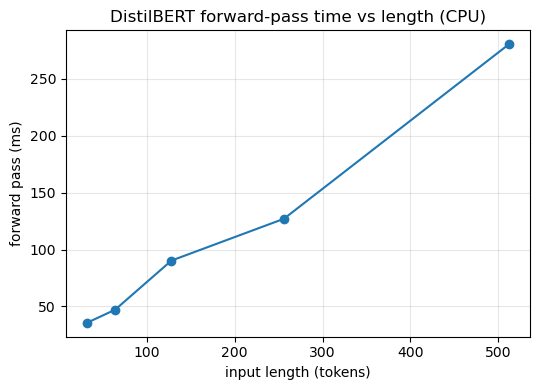

time ratio 512/256: 2.21 (2.0 would be linear, 4.0 fully quadratic)


In [37]:
base = ("This movie was a long and winding story with many characters and surprising twists. " * 80)
lengths, ms = [32, 64, 128, 256, 512], []
for L in lengths:
    x = tok(base, truncation=True, max_length=L, return_tensors="pt")
    assert x["input_ids"].shape[1] == L
    enc_model(**x)                                           # warm-up
    t = []
    for _ in range(10):
        s = time.perf_counter(); enc_model(**x); t.append(time.perf_counter() - s)
    ms.append(1000 * np.mean(t)); print(f"L={L:3d}: {ms[-1]:.1f} ms")
plt.figure(figsize=(5.5, 4)); plt.plot(lengths, ms, "o-"); plt.xlabel("input length (tokens)"); plt.ylabel("forward pass (ms)")
plt.title("DistilBERT forward-pass time vs length (CPU)"); plt.grid(alpha=.3)
savefig("time_vs_length.png"); plt.show()
print("time ratio 512/256:", round(ms[-1] / ms[-2], 2), "(2.0 would be linear, 4.0 fully quadratic)")

Attention compares every token with every other token, so the attention part grows with L². Doubling the length therefore costs up to 4× in that part. On a CPU at small sizes, the feed-forward and projection layers (linear in L) dominate, so the measured curve often looks **closer to linear** than quadratic until L is large — read the 512/256 ratio above honestly. It still explains the 512-token limit: longer inputs become quickly expensive, which is why windows are fixed.

## 6.4 Hallucination check

In [38]:
facts = [("The capital of Australia is", "canberra"),
         ("The author of the novel Pride and Prejudice is", "austen"),
         ("The inventor of the telephone was", "bell")]
rows = []
for p, key in facts:
    pi = gtok(p, return_tensors="pt")
    o = gpt.generate(**pi, max_new_tokens=30, do_sample=False, pad_token_id=gtok.eos_token_id)
    text = gtok.decode(o[0], skip_special_tokens=True).replace("\n", " ")
    rows.append({"prompt": p, "output": text, "contains expected answer": key in text.lower()})
hall = pd.DataFrame(rows); hall

,prompt,output,contains expected answer
0,The capital of Australia is,"The capital of Australia is the world's largest producer of coal, and the country's largest coal-fired power station. The coal industry is also the world's largest",False
1,The author of the novel Pride and Prejudice is,The author of the novel Pride and Prejudice is a former member of the National Security Council. The author of the novel is a former member of the National Security Council. The author,False
2,The inventor of the telephone was,The inventor of the telephone was a man named John D. Rockefeller. He was a man who had been a member of the Rockefeller family for many years. He was a man who,False


In [39]:
# Fill in YOUR judgement after reading the outputs above: "correct", "partly correct" or "wrong".
grades = ["TODO", "TODO", "TODO"]
hall["my grade"] = grades
hall[["prompt", "contains expected answer", "my grade"]]

,prompt,contains expected answer,my grade
0,The capital of Australia is,False,TODO
1,The author of the novel Pride and Prejudice is,False,TODO
2,The inventor of the telephone was,False,TODO


GPT-2 only learns which word is *likely* next, not what is *true*. Even when a fact is right, the continuation often adds invented details, and an answer can look fluent but be wrong. Generative models are therefore unreliable as a source of facts unless checked or connected to a trusted source — this is the **hallucination** disadvantage from Task 1.3.

## 6.5 Mini application — `text_toolkit()`

In [41]:
MAX_WORDS = 400
def text_toolkit(text):
    if not isinstance(text, str) or not text.strip():
        return {"sentiment": "n/a", "score": None,
                "summary": "Error: empty input, please provide some text.", "french": ""}
    note = ""
    words = text.split()
    if len(words) > MAX_WORDS:
        text = " ".join(words[:MAX_WORDS])
        note = f" (input truncated to first {MAX_WORDS} words)"
    s = clf(text, truncation=True, max_length=512)[0]
    summ = summarize(text, max_length=60, min_length=min(20, max(5, len(text.split()) // 2)))
    fr = translate(summ)
    return {"sentiment": s["label"], "score": round(s["score"], 3), "summary": summ + note, "french": fr}

## 6.6 Reflection — What I learned about Transformers
*(Replace the bracketed parts with your own numbers and words after running the notebook.)*

**(a) Best understood / still unclear.** I now understand scaled dot-product attention best, because I could build it in NumPy and verify it against DistilBERT with a maximum difference of [your value]. The part still unclear is [e.g. how different heads specialise and why].

**(b) Theory matched / surprise.** Matched: the causal mask — GPT-2's upper triangle was zero (`np.triu` max = [value]) exactly like my NumPy mask, and my greedy loop gave the same text as `generate()`. Surprise: [e.g. the cross-attention heatmap was only a rough alignment / the CPU timing looked closer to linear than quadratic].

**(c) Two disadvantages measured.** (1) Fixed context window / cost: accuracy changed from [acc@64] at 64 tokens to [acc@512] at 512 tokens, [over] of 200 reviews still exceeded 512 tokens, and the forward pass took [ms@256] ms at 256 vs [ms@512] ms at 512 tokens. (2) Hallucination: GPT-2 graded [x/3] correct on three simple factual prompts.

**(d) Application I would build.** A customer-feedback assistant that classifies sentiment and summarises long reviews — it needs an **encoder** model for classification and an **encoder-decoder** (or decoder-only) model for summaries.

## 6.7 Notebook quality & reproducibility
Run **Kernel → Restart & Run All**, then export with `jupyter nbconvert --to html DL_PR6.ipynb`. The cell below writes `requirements.txt` with the versions actually installed.

In [42]:
from importlib.metadata import version
pk = ["transformers", "torch", "datasets", "matplotlib", "seaborn", "numpy", "pandas", "scikit-learn"]
with open("requirements.txt", "w") as f:
    for p in pk: f.write(f"{p}=={version(p)}\n")
print(open("requirements.txt").read())

transformers==5.22.1
torch==2.14.0
datasets==5.1.0
matplotlib==3.10.6
seaborn==0.13.2
numpy==2.5.4
pandas==2.3.3
scikit-learn==1.7.2

